# Stage 3 - CIFAR-10 AugMix ResNet-18 (Google Colab)

This notebook prepares the second base classifier for the project. It keeps the approved CIFAR-style ResNet-18 and standard-model training recipe; AugMix is the training-method difference. It uses only the CIFAR-10 training set and does not run clean, calibration, evaluation, or CIFAR-10-C inference.

The AugMix settings follow the CIFAR-10 defaults in the authors' reference implementation: severity 3, width 3, random chain depth 1-3, and alpha 1.0. The full method uses one clean view and two independently augmented views with cross-entropy on the clean view plus a Jensen-Shannon consistency loss. The default augmentation pool excludes brightness, contrast, color, and sharpness operations. Source: https://github.com/google-research/augmix

Run through the temporary sanity, smoke, and timing cells first. They use a separate temporary model. Official 75-epoch training remains disabled by default and will start from a fresh initialization only after you enable it.

Before running, copy the project folder to Google Drive, including:
- `src/models.py`
- `data/raw/cifar-10-batches-py/` or the CIFAR-10 batch ZIP
- the three saved split files in `data/splits/`

The split files are checked for integrity but are not used for training or checkpoint selection.


## 1. Colab runtime and accelerator check

The official training run requires CUDA. This cell prints Python, PyTorch, torchvision, CUDA availability, the GPU name, and total GPU memory, then stops if CUDA is unavailable.


In [3]:
import gc
import csv
import json
import math
import os
import platform
import random
import sys
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import CIFAR10

print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is required for the official training run. In Colab, select "
        "Runtime > Change runtime type > T4 GPU (or another CUDA GPU), then rerun."
    )

DEVICE = torch.device("cuda:0")
GPU_NAME = torch.cuda.get_device_name(DEVICE)
GPU_PROPERTIES = torch.cuda.get_device_properties(DEVICE)
GPU_MEMORY_GIB = GPU_PROPERTIES.total_memory / (1024 ** 3)
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(f"GPU memory: {GPU_MEMORY_GIB:.2f} GiB")

torch.backends.cudnn.benchmark = True
print(f"torch.backends.cudnn.benchmark: {torch.backends.cudnn.benchmark}")


Python: 3.13.15
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA available: True
Selected device: cuda:0
GPU name: Tesla T4
GPU memory: 14.56 GiB
torch.backends.cudnn.benchmark: True


## 2. Project location and Drive persistence

Set the project root below. The default assumes a copy of this project folder is at My Drive/conformal_shift. The dedicated output folder is `checkpoints/resnet18_augmix_colab/`, separate from the completed standard-model run.

The notebook does not download CIFAR-10 or recreate split indices. If the extracted CIFAR-10 Python batches are absent, setup extracts one matching batch ZIP already in the project root or `data/raw/`.


In [4]:
import shutil
import zipfile

USE_GOOGLE_DRIVE = True
GOOGLE_DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/conformal_shift")
PROJECT_ROOT_OVERRIDE = None  # Set a Path/string here to use a different project root.

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError(
            "Google Drive mounting is available inside Google Colab. "
            "Set USE_GOOGLE_DRIVE=False and PROJECT_ROOT_OVERRIDE when running elsewhere."
        ) from error
    drive.mount("/content/drive")
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE) if PROJECT_ROOT_OVERRIDE else GOOGLE_DRIVE_PROJECT_ROOT
else:
    PROJECT_ROOT = (
        Path(PROJECT_ROOT_OVERRIDE)
        if PROJECT_ROOT_OVERRIDE
        else Path("/content/conformal_shift")
    )

PROJECT_ROOT = PROJECT_ROOT.expanduser().resolve()
DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
MODEL_SOURCE = PROJECT_ROOT / "src" / "models.py"
OUTPUT_DIR = PROJECT_ROOT / "checkpoints" / "resnet18_augmix_colab"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CIFAR_BATCH_DIR = DATA_ROOT / "cifar-10-batches-py"
CIFAR_BATCH_FILES = [
    "data_batch_1", "data_batch_2", "data_batch_3",
    "data_batch_4", "data_batch_5", "test_batch", "batches.meta",
]
if not all((CIFAR_BATCH_DIR / name).is_file() for name in CIFAR_BATCH_FILES):
    archive_candidates = {
        path.resolve()
        for pattern in ("cifar-10-batches-py*.zip",)
        for search_root in (PROJECT_ROOT, DATA_ROOT)
        for path in search_root.glob(pattern)
    }
    if len(archive_candidates) != 1:
        raise FileNotFoundError(
            "Expected the extracted CIFAR-10 Python batches under data/raw/cifar-10-batches-py "
            "or exactly one cifar-10-batches-py*.zip in the project root/data/raw. "
            f"Found archives: {sorted(str(path) for path in archive_candidates)}"
        )
    archive_path = next(iter(archive_candidates))
    expected_members = [
        f"cifar-10-batches-py/{filename}" for filename in CIFAR_BATCH_FILES
    ]
    with zipfile.ZipFile(archive_path, "r") as archive:
        archive_members = set(archive.namelist())
        missing_members = sorted(set(expected_members) - archive_members)
        if missing_members:
            raise ValueError(f"The CIFAR-10 archive is missing expected files: {missing_members}")
        bad_member = archive.testzip()
        if bad_member is not None:
            raise ValueError(f"CIFAR-10 ZIP CRC check failed for: {bad_member}")
        CIFAR_BATCH_DIR.mkdir(parents=True, exist_ok=True)
        for member in expected_members:
            destination = CIFAR_BATCH_DIR / Path(member).name
            with archive.open(member, "r") as source, destination.open("wb") as target:
                target.write(source.read())
    print(f"Extracted the CIFAR-10 Python batches from: {archive_path}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Data root: {DATA_ROOT}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"CIFAR-10 batch directory: {CIFAR_BATCH_DIR}")

required_paths = [
    MODEL_SOURCE,
    *[CIFAR_BATCH_DIR / name for name in CIFAR_BATCH_FILES],
    *[SPLIT_DIR / f"clean_test_split_seed{seed}.npz" for seed in (42, 43, 44)],
]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        "Project files are missing. Copy the project data, src/models.py, and split files "
        f"to the configured Drive project root. Missing: {missing_paths}"
    )

# Confirm each saved split remains disjoint and has the expected sizes.
for split_seed in (42, 43, 44):
    split_path = SPLIT_DIR / f"clean_test_split_seed{split_seed}.npz"
    with np.load(split_path, allow_pickle=False) as split:
        calibration_indices = split["calibration_indices"].astype(np.int64)
        evaluation_indices = split["evaluation_indices"].astype(np.int64)
    if calibration_indices.size != 5_000 or evaluation_indices.size != 5_000:
        raise ValueError(f"Unexpected split sizes in {split_path}")
    if np.intersect1d(calibration_indices, evaluation_indices).size:
        raise ValueError(f"Calibration/evaluation overlap in {split_path}")
print("Project files and all three disjoint split files: PASS")

sys.path.insert(0, str(PROJECT_ROOT))
from src.models import resnet18_cifar

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/conformal_shift
Data root: /content/drive/MyDrive/conformal_shift/data/raw
Output directory: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_augmix_colab
CIFAR-10 batch directory: /content/drive/MyDrive/conformal_shift/data/raw/cifar-10-batches-py
Project files and all three disjoint split files: PASS


## 3. Fixed training and AugMix configuration

The model, data source, batch size, 75 epochs, SGD optimizer, initial learning rate, momentum, weight decay, cosine schedule, CIFAR-10 normalization, data-loader settings, AMP, and cuDNN benchmarking match the completed standard-model run.

AugMix uses width 3, severity 3, stochastic depth from 1 to 3, and alpha 1.0 for its Dirichlet and Beta mixing draws. Each example produces a clean view and two independent AugMix views. The training objective is `cross_entropy(clean_logits, label) + 12 * JSD(clean, aug1, aug2)`. The timing cell reports that each batch of 64 training examples expands to 192 images for the model forward pass.

The author reference code is based on a different CIFAR normalization convention; this notebook deliberately uses the project-approved CIFAR-10 mean and standard deviation so the two base models remain comparable.


In [6]:
SEED = 42
EPOCHS = 75
BATCH_SIZE = 64
INITIAL_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
PIN_MEMORY = True
USE_AMP = True
RESUME_TRAINING = False
RUN_OFFICIAL_TRAINING = False
RUN_GPU_PREFLIGHT = False

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

AUGMIX_SEVERITY = 3
AUGMIX_WIDTH = 3
AUGMIX_DEPTH = -1  # Randomly sample an operation-chain depth from 1, 2, or 3.
AUGMIX_ALPHA = 1.0
JSD_LOSS_COEFFICIENT = 12.0
AUGMIX_OPERATION_NAMES = [
    "autocontrast", "equalize", "posterize", "rotate", "solarize",
    "shear_x", "shear_y", "translate_x", "translate_y",
]

TRAINING_CONFIG = {
    "run_name": "augmix_resnet18_cifar10",
    "model": "CIFAR-style ResNet-18",
    "stem_kernel_size": 3,
    "stem_stride": 1,
    "initial_maxpool": False,
    "pretrained_weights": None,
    "num_classes": 10,
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "SGD",
    "initial_lr": INITIAL_LR,
    "momentum": MOMENTUM,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR",
    "scheduler_t_max": EPOCHS,
    "scheduler_eta_min": 0.0,
    "base_augmentation": ["RandomCrop(32, padding=4)", "RandomHorizontalFlip()"],
    "augmix": {
        "severity": AUGMIX_SEVERITY,
        "mixture_width": AUGMIX_WIDTH,
        "mixture_depth": AUGMIX_DEPTH,
        "mixture_depth_interpretation": "random integer from 1 through 3",
        "alpha": AUGMIX_ALPHA,
        "views_per_example": ["clean", "augmix_1", "augmix_2"],
        "jsd_loss_coefficient": JSD_LOSS_COEFFICIENT,
        "operation_pool": AUGMIX_OPERATION_NAMES,
        "include_brightness_contrast_color_sharpness": False,
    },
    "normalization_mean": list(CIFAR_MEAN),
    "normalization_std": list(CIFAR_STD),
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "use_amp": USE_AMP,
    "cudnn_benchmark": True,
}
print(json.dumps(TRAINING_CONFIG, indent=2))
print(f"RESUME_TRAINING: {RESUME_TRAINING}")
print(f"RUN_OFFICIAL_TRAINING: {RUN_OFFICIAL_TRAINING}")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)

print(f'Effective recovery settings: resume={RESUME_TRAINING}, run={RUN_OFFICIAL_TRAINING}')

{
  "run_name": "augmix_resnet18_cifar10",
  "model": "CIFAR-style ResNet-18",
  "stem_kernel_size": 3,
  "stem_stride": 1,
  "initial_maxpool": false,
  "pretrained_weights": null,
  "num_classes": 10,
  "seed": 42,
  "epochs": 75,
  "batch_size": 64,
  "optimizer": "SGD",
  "initial_lr": 0.05,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "scheduler": "CosineAnnealingLR",
  "scheduler_t_max": 75,
  "scheduler_eta_min": 0.0,
  "base_augmentation": [
    "RandomCrop(32, padding=4)",
    "RandomHorizontalFlip()"
  ],
  "augmix": {
    "severity": 3,
    "mixture_width": 3,
    "mixture_depth": -1,
    "mixture_depth_interpretation": "random integer from 1 through 3",
    "alpha": 1.0,
    "views_per_example": [
      "clean",
      "augmix_1",
      "augmix_2"
    ],
    "jsd_loss_coefficient": 12.0,
    "operation_pool": [
      "autocontrast",
      "equalize",
      "posterize",
      "rotate",
      "solarize",
      "shear_x",
      "shear_y",
      "translate_x",
      "translate

## 4. CIFAR-10 training data and AugMix views

Random crop and horizontal flip are applied once to each CIFAR-10 training image. From that image, the dataset returns the normalized clean view and two independent AugMix views. The CIFAR-10 test set is not loaded here.

Inspect the example below: the clean image should remain recognizable and the two AugMix images should have valid 32x32 shapes. The augmentation operations are sampled from the author's default pool, which excludes brightness, contrast, color, and sharpness.


Training images: 50,000
Each view tensor shape: (3, 32, 32)
Number of views per training example: 3
Normalization mean: (0.4914, 0.4822, 0.4465)
Normalization std: (0.247, 0.2435, 0.2616)


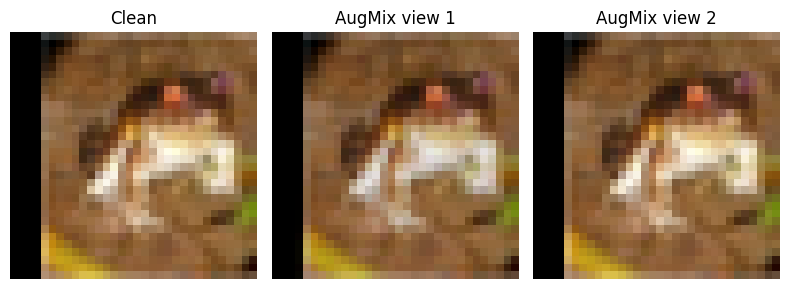

In [7]:
IMAGE_SIZE = 32

base_train_transform = transforms.Compose([
    transforms.RandomCrop(IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
])
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

train_dataset = CIFAR10(
    root=str(DATA_ROOT),
    train=True,
    download=False,
    transform=base_train_transform,
)
if len(train_dataset) != 50_000:
    raise ValueError(f"Expected 50,000 CIFAR-10 training images; found {len(train_dataset)}")


def sample_level(max_level):
    return float(np.random.uniform(0.1, max_level))


def int_parameter(level, max_value):
    return int(level * max_value / 10)


def float_parameter(level, max_value):
    return float(level) * max_value / 10.0


def signed(value):
    return -value if np.random.random() > 0.5 else value


def op_autocontrast(image, severity):
    return ImageOps.autocontrast(image)


def op_equalize(image, severity):
    return ImageOps.equalize(image)


def op_posterize(image, severity):
    bits_to_remove = int_parameter(sample_level(severity), 4)
    return ImageOps.posterize(image, 4 - bits_to_remove)


def op_rotate(image, severity):
    degrees = signed(int_parameter(sample_level(severity), 30))
    return image.rotate(degrees, resample=Image.Resampling.BILINEAR)


def op_solarize(image, severity):
    threshold = 256 - int_parameter(sample_level(severity), 256)
    return ImageOps.solarize(image, threshold)


def op_shear_x(image, severity):
    shear = signed(float_parameter(sample_level(severity), 0.3))
    return image.transform(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Transform.AFFINE,
        (1, shear, 0, 0, 1, 0),
        resample=Image.Resampling.BILINEAR,
    )


def op_shear_y(image, severity):
    shear = signed(float_parameter(sample_level(severity), 0.3))
    return image.transform(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Transform.AFFINE,
        (1, 0, 0, shear, 1, 0),
        resample=Image.Resampling.BILINEAR,
    )


def op_translate_x(image, severity):
    offset = signed(int_parameter(sample_level(severity), IMAGE_SIZE / 3))
    return image.transform(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Transform.AFFINE,
        (1, 0, offset, 0, 1, 0),
        resample=Image.Resampling.BILINEAR,
    )


def op_translate_y(image, severity):
    offset = signed(int_parameter(sample_level(severity), IMAGE_SIZE / 3))
    return image.transform(
        (IMAGE_SIZE, IMAGE_SIZE),
        Image.Transform.AFFINE,
        (1, 0, 0, 0, 1, offset),
        resample=Image.Resampling.BILINEAR,
    )


AUGMIX_OPERATIONS = [
    op_autocontrast,
    op_equalize,
    op_posterize,
    op_rotate,
    op_solarize,
    op_shear_x,
    op_shear_y,
    op_translate_x,
    op_translate_y,
]


class AugMixTrainingDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def make_augmix_view(self, image):
        clean_tensor = preprocess(image)
        chain_weights = np.random.dirichlet(
            np.full(AUGMIX_WIDTH, AUGMIX_ALPHA, dtype=np.float64)
        )
        mix_with_clean = float(np.random.beta(AUGMIX_ALPHA, AUGMIX_ALPHA))
        mixed_augmented = torch.zeros_like(clean_tensor)

        for chain_weight in chain_weights:
            augmented_image = image.copy()
            if AUGMIX_DEPTH == -1:
                chain_depth = int(np.random.randint(1, 4))
            else:
                chain_depth = AUGMIX_DEPTH
            for _ in range(chain_depth):
                operation = AUGMIX_OPERATIONS[np.random.randint(len(AUGMIX_OPERATIONS))]
                augmented_image = operation(augmented_image, AUGMIX_SEVERITY)
            mixed_augmented += float(chain_weight) * preprocess(augmented_image)

        return (1.0 - mix_with_clean) * clean_tensor + mix_with_clean * mixed_augmented

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        clean_view = preprocess(image)
        augmix_view_1 = self.make_augmix_view(image)
        augmix_view_2 = self.make_augmix_view(image)
        return (clean_view, augmix_view_1, augmix_view_2), label


augmix_train_dataset = AugMixTrainingDataset(train_dataset)
if tuple(train_dataset[0][0].size) != (IMAGE_SIZE, IMAGE_SIZE):
    raise ValueError(f"Unexpected source image size: {train_dataset[0][0].size}")
example_views, example_label = augmix_train_dataset[0]
if any(tuple(view.shape) != (3, IMAGE_SIZE, IMAGE_SIZE) for view in example_views):
    raise ValueError("AugMix must return three tensors shaped (3, 32, 32).")
print(f"Training images: {len(augmix_train_dataset):,}")
print(f"Each view tensor shape: {tuple(example_views[0].shape)}")
print(f"Number of views per training example: {len(example_views)}")
print(f"Normalization mean: {CIFAR_MEAN}")
print(f"Normalization std: {CIFAR_STD}")


def show_normalized_image(ax, tensor, title):
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(3, 1, 1)
    image = (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, tensor, title in zip(
    axes, example_views, ["Clean", "AugMix view 1", "AugMix view 2"]
):
    show_normalized_image(ax, tensor, title)
plt.tight_layout()
plt.show()


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_train_loader(generator):
    loader_kwargs = {
        "dataset": augmix_train_dataset,
        "batch_size": BATCH_SIZE,
        "shuffle": True,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
        "generator": generator,
        "worker_init_fn": seed_worker,
        "drop_last": False,
    }
    if NUM_WORKERS > 0:
        loader_kwargs["persistent_workers"] = False
        loader_kwargs["prefetch_factor"] = 2
    return DataLoader(**loader_kwargs)


## 5. Optional AugMix GPU preflight

This temporary-model preflight checks the AugMix training step and measures Colab GPU time and memory. It was run previously; its saved output is retained below. `RUN_GPU_PREFLIGHT` defaults to `False`, so rerunning this cell skips the GPU workload. Set it to `True` only when validating a new runtime. Official training is controlled separately by `RUN_OFFICIAL_TRAINING`.


In [8]:
def augmix_training_step(model, optimizer, scaler, views, labels):
    clean_images, augmix_images_1, augmix_images_2 = [
        view.to(DEVICE, non_blocking=True) for view in views
    ]
    labels = labels.to(DEVICE, non_blocking=True)
    batch_size = labels.size(0)
    images_all = torch.cat([clean_images, augmix_images_1, augmix_images_2], dim=0)
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
        logits_all = model(images_all)
        if tuple(logits_all.shape) != (3 * batch_size, 10):
            raise ValueError(
                f"Expected logits shaped {(3 * batch_size, 10)}, got {tuple(logits_all.shape)}"
            )
        logits_clean, logits_aug_1, logits_aug_2 = logits_all.split(batch_size, dim=0)
        cross_entropy = F.cross_entropy(logits_clean, labels)

        probabilities = [
            torch.softmax(logits.float(), dim=1)
            for logits in (logits_clean, logits_aug_1, logits_aug_2)
        ]
        mean_probability = torch.stack(probabilities, dim=0).mean(dim=0)
        log_mean_probability = mean_probability.clamp_min(1e-7).log()
        jsd = sum(
            F.kl_div(log_mean_probability, probability, reduction="batchmean")
            for probability in probabilities
        ) / 3.0
        loss = cross_entropy + JSD_LOSS_COEFFICIENT * jsd

    if USE_AMP:
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
    else:
        loss.backward()
        optimizer.step()

    return loss.detach(), cross_entropy.detach(), jsd.detach(), tuple(logits_all.shape)


if RUN_GPU_PREFLIGHT:
    timing_generator = torch.Generator().manual_seed(SEED + 10_000)
    timing_loader = make_train_loader(timing_generator)
    timing_iterator = iter(timing_loader)
    timing_model = resnet18_cifar(num_classes=10).to(DEVICE)
    timing_optimizer = torch.optim.SGD(
        timing_model.parameters(),
        lr=INITIAL_LR,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )
    timing_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    # Two-batch forward/backward and optimizer-update sanity check.
    initial_parameter = next(timing_model.parameters()).detach().clone()
    sanities = []
    timing_model.train()
    for _ in range(2):
        views, labels = next(timing_iterator)
        values = augmix_training_step(timing_model, timing_optimizer, timing_scaler, views, labels)
        if not all(torch.isfinite(value).all() for value in values[:3]):
            raise FloatingPointError("Non-finite AugMix sanity-check loss.")
        sanities.append(values)
    if torch.equal(initial_parameter, next(timing_model.parameters()).detach()):
        raise RuntimeError("The temporary optimizer step did not change model parameters.")
    print("Two-batch forward/backward/optimizer sanity check: PASS")
    print(f"Example branch logits shape: {sanities[-1][3][0] // 3, 10}")
    print(f"Sanity total losses: {[round(value[0].item(), 4) for value in sanities]}")

    # Short smoke-training run, still on the temporary model only.
    smoke_losses = []
    for _ in range(3):
        views, labels = next(timing_iterator)
        total_loss, _, _, _ = augmix_training_step(
            timing_model, timing_optimizer, timing_scaler, views, labels
        )
        if not torch.isfinite(total_loss):
            raise FloatingPointError("Non-finite loss during the three-batch smoke test.")
        smoke_losses.append(total_loss.item())
    print("Three-batch smoke training: PASS")
    print(f"Smoke losses: {[round(value, 4) for value in smoke_losses]}")

    warmup_batches = 5
    measured_batches = 40
    for _ in range(warmup_batches):
        views, labels = next(timing_iterator)
        augmix_training_step(timing_model, timing_optimizer, timing_scaler, views, labels)

    torch.cuda.synchronize(DEVICE)
    torch.cuda.reset_peak_memory_stats(DEVICE)
    timing_start = time.perf_counter()
    timing_loss_total = torch.zeros((), device=DEVICE)
    timing_ce_total = torch.zeros((), device=DEVICE)
    timing_jsd_total = torch.zeros((), device=DEVICE)
    timing_examples = 0
    for _ in range(measured_batches):
        views, labels = next(timing_iterator)
        total_loss, cross_entropy, jsd, _ = augmix_training_step(
            timing_model, timing_optimizer, timing_scaler, views, labels
        )
        batch_count = labels.size(0)
        timing_loss_total += total_loss * batch_count
        timing_ce_total += cross_entropy * batch_count
        timing_jsd_total += jsd * batch_count
        timing_examples += batch_count
    torch.cuda.synchronize(DEVICE)
    timing_seconds = time.perf_counter() - timing_start

    batches_per_epoch = math.ceil(len(augmix_train_dataset) / BATCH_SIZE)
    seconds_per_batch = timing_seconds / measured_batches
    estimated_epoch_seconds = seconds_per_batch * batches_per_epoch
    estimated_75_epoch_seconds = estimated_epoch_seconds * EPOCHS
    peak_memory_gib = torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 3)

    print(f"Colab GPU: {GPU_NAME}")
    print(f"Approximate GPU memory: {GPU_MEMORY_GIB:.2f} GiB total")
    print(f"Training examples per batch: {BATCH_SIZE}; views per example: 3")
    print(f"Effective model input shape: ({3 * BATCH_SIZE}, 3, 32, 32)")
    print(f"Logits shape: ({3 * BATCH_SIZE}, 10); each branch: ({BATCH_SIZE}, 10)")
    print(f"AMP enabled: {USE_AMP}")
    print(f"cuDNN benchmark: {torch.backends.cudnn.benchmark}")
    print(f"Measured batches: {measured_batches} ({timing_examples:,} training examples, {3 * timing_examples:,} views)")
    print(f"Timing mean total loss: {(timing_loss_total / timing_examples).item():.4f}")
    print(f"Timing mean clean cross-entropy: {(timing_ce_total / timing_examples).item():.4f}")
    print(f"Timing mean JSD: {(timing_jsd_total / timing_examples).item():.4f}")
    print(f"Measured time: {timing_seconds:.2f} seconds ({seconds_per_batch:.3f} sec/batch)")
    print(f"Peak allocated GPU memory: {peak_memory_gib:.2f} GiB")
    print(f"Estimated epoch time: {estimated_epoch_seconds / 60:.1f} minutes")
    print(f"Estimated 75-epoch time: {estimated_75_epoch_seconds / 3600:.2f} hours")
    print("The temporary AugMix model, optimizer, scaler, and loader will now be discarded.")

    del timing_model, timing_optimizer, timing_scaler, timing_loader, timing_iterator
    del timing_loss_total, timing_ce_total, timing_jsd_total, initial_parameter
    # Keep augmix_training_step defined; the official loop uses the same tested objective.
    gc.collect()
    torch.cuda.empty_cache()
else:
    print("GPU preflight skipped; set RUN_GPU_PREFLIGHT=True to recheck this Colab runtime.")


Two-batch forward/backward/optimizer sanity check: PASS
Example branch logits shape: (64, 10)
Sanity total losses: [2.5064, 2.8049]
Three-batch smoke training: PASS
Smoke losses: [3.3417, 3.7622, 4.8039]
Colab GPU: Tesla T4
Approximate GPU memory: 14.56 GiB total
Training examples per batch: 64; views per example: 3
Effective model input shape: (192, 3, 32, 32)
Logits shape: (192, 10); each branch: (64, 10)
AMP enabled: True
cuDNN benchmark: True
Measured batches: 40 (2,560 training examples, 7,680 views)
Timing mean total loss: 4.0411
Timing mean clean cross-entropy: 3.8976
Timing mean JSD: 0.0120
Measured time: 9.18 seconds (0.230 sec/batch)
Peak allocated GPU memory: 0.58 GiB
Estimated epoch time: 3.0 minutes
Estimated 75-epoch time: 3.74 hours
The temporary AugMix model, optimizer, scaler, and loader will now be discarded.


## 6. Official checkpoint detection

The output path is separate from the standard model. This cell reports whether an AugMix checkpoint exists and prints its saved epoch and configuration. It does not resume automatically. The training cell checks that the configuration matches before any resume.


In [5]:
LATEST_CHECKPOINT_PATH = OUTPUT_DIR / "latest_checkpoint.pt"
FINAL_CHECKPOINT_PATH = OUTPUT_DIR / "final_checkpoint.pt"
FINAL_MODEL_PATH = OUTPUT_DIR / "final_model.pt"
CONFIG_PATH = OUTPUT_DIR / "training_config.json"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
LOSS_HISTORY_PATH = OUTPUT_DIR / "training_loss_history.csv"
LR_HISTORY_PATH = OUTPUT_DIR / "learning_rate_history.csv"

def checkpoint_candidate():
    if LATEST_CHECKPOINT_PATH.is_file():
        return LATEST_CHECKPOINT_PATH
    if FINAL_CHECKPOINT_PATH.is_file():
        return FINAL_CHECKPOINT_PATH
    return None

existing_checkpoint_path = checkpoint_candidate()
if existing_checkpoint_path is None:
    print("No official checkpoint found -> an explicitly enabled run will start fresh at epoch 0.")
else:
    existing_state = torch.load(
        existing_checkpoint_path, map_location="cpu", weights_only=False
    )
    required_checkpoint_keys = {
        "checkpoint_type", "epoch_completed", "config", "model_state_dict",
        "optimizer_state_dict", "scheduler_state_dict", "scaler_state_dict",
        "history", "loader_generator_state", "python_rng_state",
        "numpy_rng_state", "torch_rng_state", "cuda_rng_state",
    }
    if not required_checkpoint_keys.issubset(existing_state):
        raise ValueError(f"Checkpoint is missing required resume fields: {existing_checkpoint_path}")
    if existing_state["checkpoint_type"] != "official_resnet18_augmix":
        raise ValueError("The found checkpoint is not an official standard ResNet-18 run.")
    print(f"Official checkpoint found: {existing_checkpoint_path}")
    print(f"Completed epoch: {existing_state['epoch_completed']}")
    print("Saved configuration:")
    print(json.dumps(existing_state["config"], indent=2))

Official checkpoint found: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_augmix_colab/latest_checkpoint.pt
Completed epoch: 56
Saved configuration:
{
  "run_name": "augmix_resnet18_cifar10",
  "model": "CIFAR-style ResNet-18",
  "stem_kernel_size": 3,
  "stem_stride": 1,
  "initial_maxpool": false,
  "pretrained_weights": null,
  "num_classes": 10,
  "seed": 42,
  "epochs": 75,
  "batch_size": 64,
  "optimizer": "SGD",
  "initial_lr": 0.05,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "scheduler": "CosineAnnealingLR",
  "scheduler_t_max": 75,
  "scheduler_eta_min": 0.0,
  "base_augmentation": [
    "RandomCrop(32, padding=4)",
    "RandomHorizontalFlip()"
  ],
  "augmix": {
    "severity": 3,
    "mixture_width": 3,
    "mixture_depth": -1,
    "mixture_depth_interpretation": "random integer from 1 through 3",
    "alpha": 1.0,
    "views_per_example": [
      "clean",
      "augmix_1",
      "augmix_2"
    ],
    "jsd_loss_coefficient": 12.0,
    "operation_pool": [
  

## 7. Recoverable official training loop

The official loop uses only the 50,000 CIFAR-10 training images and the fixed 75-epoch recipe. It does not load or evaluate any calibration/evaluation examples. After every epoch, it saves model, optimizer, scheduler, AMP scaler, random states, completed epoch, configuration, and full training history to Drive.

Training is disabled by default. After reviewing the sanity checks and timing estimate, set `RUN_OFFICIAL_TRAINING=True` to begin a fresh run. Keep `RESUME_TRAINING=False` unless intentionally resuming a matching AugMix checkpoint.


Resuming AugMix training from completed epoch 56.
Epoch 57/75 | objective 0.2720 | CE 0.1251 | JSD 0.0122 | LR 0.007508 | epoch 3.53 min | cumulative 3.01 hr
Epoch 58/75 | objective 0.2639 | CE 0.1158 | JSD 0.0123 | LR 0.006776 | epoch 3.75 min | cumulative 3.08 hr
Epoch 59/75 | objective 0.2497 | CE 0.1065 | JSD 0.0119 | LR 0.006075 | epoch 3.64 min | cumulative 3.14 hr
Epoch 60/75 | objective 0.2336 | CE 0.0971 | JSD 0.0114 | LR 0.005408 | epoch 3.54 min | cumulative 3.20 hr
Epoch 61/75 | objective 0.2219 | CE 0.0886 | JSD 0.0111 | LR 0.004775 | epoch 3.53 min | cumulative 3.26 hr
Epoch 62/75 | objective 0.2134 | CE 0.0807 | JSD 0.0111 | LR 0.004177 | epoch 3.51 min | cumulative 3.31 hr
Epoch 63/75 | objective 0.2026 | CE 0.0737 | JSD 0.0107 | LR 0.003616 | epoch 3.59 min | cumulative 3.37 hr
Epoch 64/75 | objective 0.1834 | CE 0.0655 | JSD 0.0098 | LR 0.003092 | epoch 3.66 min | cumulative 3.43 hr
Epoch 65/75 | objective 0.1692 | CE 0.0575 | JSD 0.0093 | LR 0.002607 | epoch 3.86 min

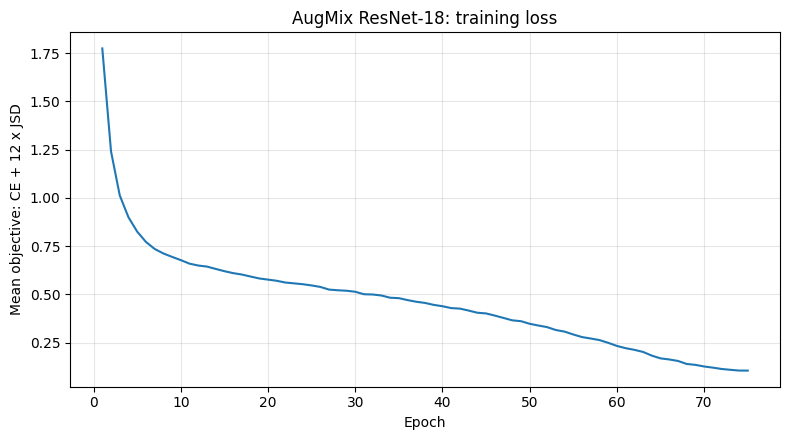

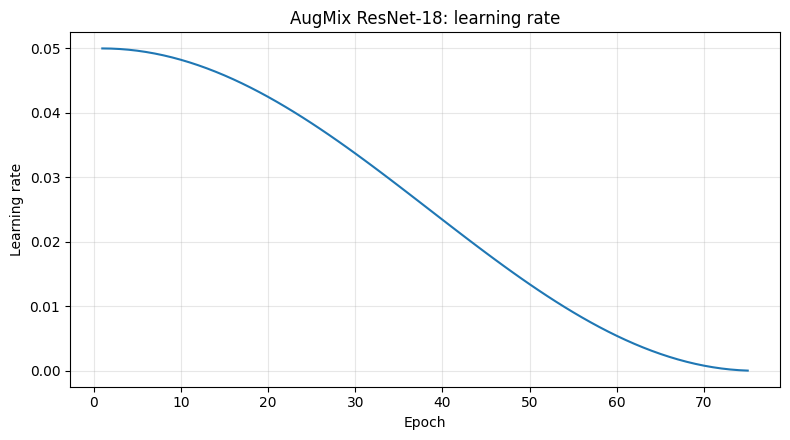

Final training objective: 0.1058
Final clean cross-entropy component: 0.0242
Final JSD component: 0.0068
Total active training time: 4.09 hours
Final model: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_augmix_colab/final_model.pt
Final recoverable checkpoint: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_augmix_colab/final_checkpoint.pt
Latest recoverable checkpoint: /content/drive/MyDrive/conformal_shift/checkpoints/resnet18_augmix_colab/latest_checkpoint.pt


In [9]:
def write_history_csv(history):
    fieldnames = [
        "epoch", "mean_train_loss", "mean_cross_entropy", "mean_jsd",
        "learning_rate", "epoch_seconds", "cumulative_elapsed_seconds",
    ]
    temporary_path = HISTORY_PATH.with_suffix(".tmp")
    with temporary_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(history)
    os.replace(temporary_path, HISTORY_PATH)

    with LOSS_HISTORY_PATH.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["epoch", "mean_train_loss", "mean_cross_entropy", "mean_jsd"])
        writer.writerows(
            (row["epoch"], row["mean_train_loss"], row["mean_cross_entropy"], row["mean_jsd"])
            for row in history
        )

    with LR_HISTORY_PATH.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.writer(output_file)
        writer.writerow(["epoch", "learning_rate"])
        writer.writerows((row["epoch"], row["learning_rate"]) for row in history)


def save_checkpoint(path, state):
    temporary_path = path.with_name(path.name + ".tmp")
    torch.save(state, temporary_path)
    os.replace(temporary_path, path)


def plot_training_history(history):
    epochs = [row["epoch"] for row in history]
    losses = [row["mean_train_loss"] for row in history]
    learning_rates = [row["learning_rate"] for row in history]

    plt.figure(figsize=(8, 4.5))
    plt.plot(epochs, losses)
    plt.xlabel("Epoch")
    plt.ylabel("Mean objective: CE + 12 x JSD")
    plt.title("AugMix ResNet-18: training loss")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "training_loss.png", dpi=160)
    plt.show()

    plt.figure(figsize=(8, 4.5))
    plt.plot(epochs, learning_rates)
    plt.xlabel("Epoch")
    plt.ylabel("Learning rate")
    plt.title("AugMix ResNet-18: learning rate")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "learning_rate.png", dpi=160)
    plt.show()


def official_training():
    candidate = checkpoint_candidate()
    if candidate is not None and not RESUME_TRAINING:
        raise RuntimeError(
            f"An official AugMix checkpoint exists at {candidate}. Set RESUME_TRAINING=True "
            "only after verifying the displayed configuration, or choose a new output directory."
        )
    if candidate is None and RESUME_TRAINING:
        raise FileNotFoundError("RESUME_TRAINING=True but no official AugMix checkpoint was found.")

    if candidate is None:
        conflicting_outputs = [
            path for path in (HISTORY_PATH, LOSS_HISTORY_PATH, LR_HISTORY_PATH, FINAL_MODEL_PATH)
            if path.exists()
        ]
        if conflicting_outputs:
            raise FileExistsError(
                f"Training outputs exist without a recoverable checkpoint: {conflicting_outputs}. "
                "Preserve them and choose a new output directory."
            )

    if CONFIG_PATH.exists():
        saved_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
        if saved_config != TRAINING_CONFIG:
            raise ValueError(
                f"Saved configuration differs from this notebook: {CONFIG_PATH}. "
                "Do not resume with changed settings."
            )
    else:
        CONFIG_PATH.write_text(json.dumps(TRAINING_CONFIG, indent=2), encoding="utf-8")

    seed_everything(SEED)
    model = resnet18_cifar(num_classes=10).to(DEVICE)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=INITIAL_LR,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=0.0
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = make_train_loader(loader_generator)
    history = []
    start_epoch = 0

    if candidate is not None:
        state = torch.load(candidate, map_location=DEVICE, weights_only=False)
        if state["config"] != TRAINING_CONFIG:
            raise ValueError("Checkpoint configuration does not match the current AugMix recipe.")
        model.load_state_dict(state["model_state_dict"])
        optimizer.load_state_dict(state["optimizer_state_dict"])
        scheduler.load_state_dict(state["scheduler_state_dict"])
        scaler.load_state_dict(state["scaler_state_dict"])
        history = state["history"]
        start_epoch = int(state["epoch_completed"])
        random.setstate(state["python_rng_state"])
        np.random.set_state(state["numpy_rng_state"])
        torch.set_rng_state(state["torch_rng_state"].cpu())
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda_rng_state"]])
        loader_generator.set_state(state["loader_generator_state"].cpu())
        print(f"Resuming AugMix training from completed epoch {start_epoch}.")
    else:
        print("Fresh official initialization: epoch 0, new AugMix model, optimizer, and scheduler.")

    if start_epoch > EPOCHS:
        raise ValueError(f"Checkpoint epoch {start_epoch} exceeds configured epochs {EPOCHS}.")
    cumulative_seconds = sum(float(row["epoch_seconds"]) for row in history)

    for epoch_index in range(start_epoch, EPOCHS):
        model.train()
        epoch_start = time.perf_counter()
        epoch_lr = float(optimizer.param_groups[0]["lr"])
        loss_sum = torch.zeros((), device=DEVICE)
        cross_entropy_sum = torch.zeros((), device=DEVICE)
        jsd_sum = torch.zeros((), device=DEVICE)
        example_count = 0

        for views, labels in train_loader:
            total_loss, cross_entropy, jsd, _ = augmix_training_step(
                model, optimizer, scaler, views, labels
            )
            batch_count = labels.size(0)
            loss_sum += total_loss * batch_count
            cross_entropy_sum += cross_entropy * batch_count
            jsd_sum += jsd * batch_count
            example_count += batch_count

        scheduler.step()
        torch.cuda.synchronize(DEVICE)
        epoch_seconds = time.perf_counter() - epoch_start
        cumulative_seconds += epoch_seconds
        mean_train_loss = (loss_sum / example_count).item()
        mean_cross_entropy = (cross_entropy_sum / example_count).item()
        mean_jsd = (jsd_sum / example_count).item()
        history.append({
            "epoch": epoch_index + 1,
            "mean_train_loss": mean_train_loss,
            "mean_cross_entropy": mean_cross_entropy,
            "mean_jsd": mean_jsd,
            "learning_rate": epoch_lr,
            "epoch_seconds": epoch_seconds,
            "cumulative_elapsed_seconds": cumulative_seconds,
        })
        write_history_csv(history)

        state = {
            "checkpoint_type": "official_resnet18_augmix",
            "epoch_completed": epoch_index + 1,
            "config": TRAINING_CONFIG,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "history": history,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state(),
            "cuda_rng_state": torch.cuda.get_rng_state_all(),
            "loader_generator_state": loader_generator.get_state(),
        }
        save_checkpoint(LATEST_CHECKPOINT_PATH, state)
        print(
            f"Epoch {epoch_index + 1:02d}/{EPOCHS} | "
            f"objective {mean_train_loss:.4f} | CE {mean_cross_entropy:.4f} | "
            f"JSD {mean_jsd:.4f} | LR {epoch_lr:.6f} | "
            f"epoch {epoch_seconds / 60:.2f} min | "
            f"cumulative {cumulative_seconds / 3600:.2f} hr"
        )

    final_state = torch.load(
        LATEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
    )
    save_checkpoint(FINAL_CHECKPOINT_PATH, final_state)
    torch.save(final_state["model_state_dict"], FINAL_MODEL_PATH)
    plot_training_history(history)
    print(f"Final training objective: {history[-1]['mean_train_loss']:.4f}")
    print(f"Final clean cross-entropy component: {history[-1]['mean_cross_entropy']:.4f}")
    print(f"Final JSD component: {history[-1]['mean_jsd']:.4f}")
    print(f"Total active training time: {cumulative_seconds / 3600:.2f} hours")
    print(f"Final model: {FINAL_MODEL_PATH}")
    print(f"Final recoverable checkpoint: {FINAL_CHECKPOINT_PATH}")
    print(f"Latest recoverable checkpoint: {LATEST_CHECKPOINT_PATH}")
    return model, history


if RUN_OFFICIAL_TRAINING:
    final_model, official_history = official_training()
else:
    print("Official AugMix training is disabled. Temporary checks only; no official state was changed.")


## 8. Outputs and review checkpoint

After a completed official run, the output folder contains `latest_checkpoint.pt`, `final_checkpoint.pt`, `final_model.pt`, `training_config.json`, `training_history.csv`, `training_loss_history.csv`, `learning_rate_history.csv`, `training_loss.png`, and `learning_rate.png`.

The checkpoint can resume after a Colab disconnect. The config and history report both the combined objective and its clean cross-entropy and JSD components. Evaluation and conformal prediction are intentionally not run in this notebook. First review the AugMix recipe and Colab timing estimate; official training only starts when you set `RUN_OFFICIAL_TRAINING=True`.
